# SMS Spam Collection: analysis

A walk through the dataset and the models trained with `spamclf`. Run `spamclf download` first.

1. What does the data look like?
2. Does the hand-written Naive Bayes match scikit-learn's?
3. Which decision threshold should a real filter use?
4. Which messages does the model get wrong, and why?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from spamclf.data import load_dataset, split_dataset
from spamclf.models import ModelName
from spamclf.plots import BLUE, ORANGE, STYLE
from spamclf.training import train_model

plt.rcParams.update(STYLE)
pd.set_option('display.max_colwidth', 110)

ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
DATA = ROOT / 'data' / 'SMSSpamCollection.tsv'

## 1. The data

Each row is one SMS labelled `ham` (legitimate) or `spam`.

In [2]:
raw = load_dataset(DATA, deduplicate=False)
df = load_dataset(DATA)
print(f'{len(raw):,} messages; {len(raw) - len(df):,} exact duplicates removed')
df['label'].value_counts().to_frame('messages').assign(
    share=lambda t: (t['messages'] / t['messages'].sum()).round(3)
)

5,574 messages; 403 exact duplicates removed


,messages,share
label,,
ham,4518,0.874
spam,653,0.126


Two facts shape everything that follows:

- **There are duplicates.** Left in, the same message can land in both the training and the test set, which leaks information and inflates every metric. `load_dataset` drops them by default.
- **The classes are imbalanced** (about 13% spam). A model that always answers `ham` is 87% accurate, so accuracy says little: precision and recall are the numbers to watch.

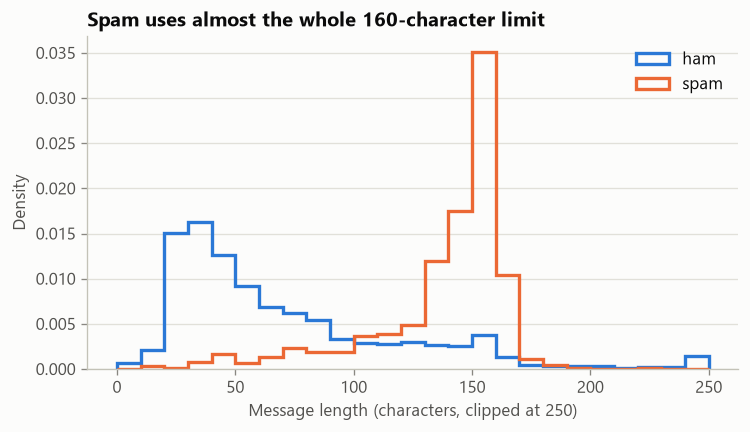

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4518.0,70.9,56.6,2.0,34.0,53.0,91.0,910.0
spam,653.0,137.7,29.8,13.0,132.0,148.0,157.0,223.0


In [3]:
df['length'] = df['text'].str.len()
bins = np.arange(0, 260, 10)

fig, ax = plt.subplots(figsize=(7, 3.6), dpi=120)
for label, color in (('ham', BLUE), ('spam', ORANGE)):
    ax.hist(df.loc[df['label'] == label, 'length'].clip(upper=250), bins=bins,
            density=True, histtype='step', linewidth=2, color=color, label=label)
ax.set_xlabel('Message length (characters, clipped at 250)')
ax.set_ylabel('Density')
ax.set_title('Spam uses almost the whole 160-character limit', loc='left',
             fontweight='bold')
ax.grid(True, axis='y')
ax.legend()
plt.show()

df.groupby('label')['length'].describe().round(1)

## 2. Hand-written Naive Bayes vs. scikit-learn

`ScratchMultinomialNB` is written with NumPy only. If the implementation is correct it must produce **the same probabilities** as `MultinomialNB`.

In [4]:
split = split_dataset(df)
ours = train_model(ModelName.NB_SCRATCH, split.X_train, split.y_train)
reference = train_model(ModelName.NB, split.X_train, split.y_train)

difference = np.abs(ours.predict_proba(split.X_test) - reference.predict_proba(split.X_test))
print(f'Largest difference in P(spam) over {len(split.X_test):,} messages: {difference.max():.2e}')

Largest difference in P(spam) over 1,035 messages: 0.00e+00


## 3. Choosing the decision threshold

By default a message is flagged when `P(spam) > 0.5`. In a real filter, sending a legitimate message to the spam folder is worse than letting one spam through, so the useful question is how much recall it costs to demand higher precision.

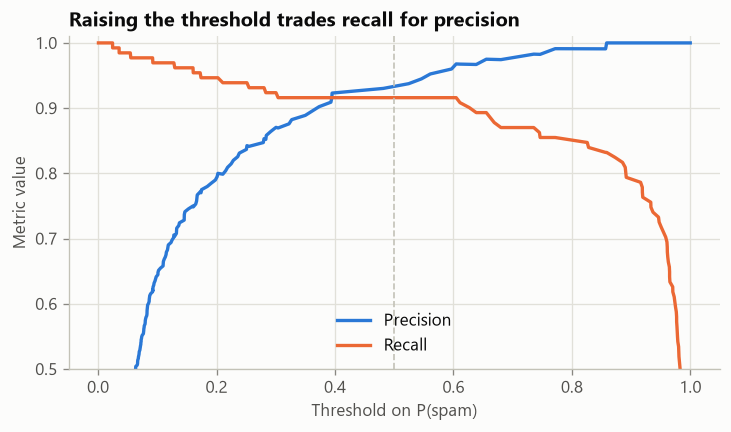

,min_precision,threshold,precision,recall
0,0.95,0.561,0.952,0.916
1,0.98,0.736,0.983,0.870
2,0.99,0.772,0.991,0.855
3,1.00,0.859,1.000,0.832


In [5]:
model = train_model(ModelName.LOGREG, split.X_train, split.y_train)
proba = model.predict_proba(split.X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(split.y_test, proba)

fig, ax = plt.subplots(figsize=(7, 3.6), dpi=120)
ax.plot(thresholds, precision[:-1], color=BLUE, linewidth=2, label='Precision')
ax.plot(thresholds, recall[:-1], color=ORANGE, linewidth=2, label='Recall')
ax.axvline(0.5, color='#c3c2b7', linewidth=1, linestyle='--')
ax.set_xlabel('Threshold on P(spam)')
ax.set_ylabel('Metric value')
ax.set_ylim(0.5, 1.01)
ax.set_title('Raising the threshold trades recall for precision', loc='left',
             fontweight='bold')
ax.grid(True)
ax.legend()
plt.show()

rows = []
for target in (0.95, 0.98, 0.99, 1.0):
    i = int(np.argmax(precision[:-1] >= target))
    rows.append({'min_precision': target, 'threshold': round(float(thresholds[i]), 3),
                 'precision': round(float(precision[i]), 3),
                 'recall': round(float(recall[i]), 3)})
pd.DataFrame(rows)

Moving the threshold from 0.5 to about 0.77 lifts precision from 0.938 to 0.991 while keeping recall at 0.855. These thresholds were read off the test set, so they are illustrative: in production the threshold would be chosen on a separate validation split.

## 4. Error analysis

Reading the mistakes is the fastest way to learn what to improve. First, the legitimate messages that were flagged as spam:

In [6]:
test = pd.DataFrame({'text': split.X_test, 'actual': split.y_test, 'p_spam': proba.round(3)})
test['predicted'] = (test['p_spam'] > 0.5).astype(int)

false_alarms = test[(test['actual'] == 0) & (test['predicted'] == 1)]
print(f"False alarms: {len(false_alarms)} of {int((test['actual'] == 0).sum())} "
      'legitimate messages')
false_alarms.sort_values('p_spam', ascending=False)[['p_spam', 'text']]

False alarms: 8 of 904 legitimate messages


,p_spam,text
474,0.857,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sm...
642,0.746,Your daily text from me – a favour this time
748,0.680,Dont you have message offer
694,0.638,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PI..."
212,0.597,I'm at work. Please call
221,0.561,Glad to see your reply.
128,0.546,Are you free now?can i call now?
744,0.524,I'm at home. Please call


Most false alarms are short messages built from words that are common in spam (*call*, *free*, *text*, *reply*, *offer*) with little other context to outweigh them. Two are automated service texts, which sit close to spam in style.

Now the other direction. Instead of listing the missed spam, compare it with the spam that was caught:

In [7]:
spam = test[test['actual'] == 1].assign(
    outcome=lambda t: np.where(t['predicted'] == 1, 'caught', 'missed'),
    has_long_number=lambda t: t['text'].str.contains(r'\d{5,}'),
    has_promo_word=lambda t: t['text'].str.contains(r'free|prize|claim|txt|won|win',
                                                     case=False),
    length=lambda t: t['text'].str.len(),
)
spam.groupby('outcome').agg(
    messages=('text', 'size'),
    share_with_5plus_digit_number=('has_long_number', 'mean'),
    share_with_promo_word=('has_promo_word', 'mean'),
    median_length=('length', 'median'),
).round(2)

,messages,share_with_5plus_digit_number,share_with_promo_word,median_length
outcome,,,,
caught,120,0.84,0.61,149.5
missed,11,0.45,0.27,90.0


The missed spam does not look like typical spam: it is shorter (median 90 characters against 150), only 45% of it contains a phone number or short code (84% of the caught spam does) and only 27% uses the usual promotional vocabulary (against 61%). With just 11 missed messages these shares are rough, but they point the same way: the model leans on numbers and promotional words, and spam written like a personal message slips through.

**Next steps this suggests:** add character n-grams and explicit features (digit ratio, upper-case ratio, presence of a URL or short code), and collect more examples of conversational spam.